# 1. Setup packages and import data

We follow the same procedure from Portfolio Assessment 1. Since this assignment is run on my Intel laptop; I install Intel's extensions for faster run time.

In [99]:
!pip install --upgrade numpy pandas ucimlrepo scikit-learn-intelex


error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try 'pacman -S
    python-xyz', where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Arch-packaged Python package,
    create a virtual environment using 'python -m venv path/to/venv'.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip.
    
    If you wish to install a non-Arch packaged Python application,
    it may be easiest to use 'pipx install xyz', which will manage a
    virtual environment for you. Make sure you have python-pipx
    installed via pacman.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detailed specification.


In [100]:
from sklearnex import patch_sklearn
patch_sklearn()

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


In [101]:
from ucimlrepo import fetch_ucirepo 
import pandas as pd
import json
  
# fetch dataset 
beijing_pm2_5 = fetch_ucirepo(id=381) 
  
# data (as pandas dataframes) 
X = pd.DataFrame(beijing_pm2_5.data.features)
y = pd.DataFrame(beijing_pm2_5.data.targets)
  
# metadata 
print("Dataset Metadata:")
print(json.dumps(beijing_pm2_5.metadata, indent = 2)) 
  
# variable information 
print("Dataset Variable Informations:")
print(beijing_pm2_5.variables) 


Dataset Metadata:
{
  "uci_id": 381,
  "name": "Beijing PM2.5",
  "repository_url": "https://archive.ics.uci.edu/dataset/381/beijing+pm2+5+data",
  "data_url": "https://archive.ics.uci.edu/static/public/381/data.csv",
  "abstract": "This hourly data set contains the PM2.5 data of US Embassy in Beijing. Meanwhile, meteorological data from Beijing Capital International Airport are also included. ",
  "area": "Climate and Environment",
  "tasks": [
    "Regression"
  ],
  "characteristics": [
    "Multivariate",
    "Time-Series"
  ],
  "num_instances": 43824,
  "num_features": 11,
  "feature_types": [
    "Integer",
    "Real"
  ],
  "demographics": [],
  "target_col": [
    "pm2.5"
  ],
  "index_col": [
    "No"
  ],
  "has_missing_values": "yes",
  "missing_values_symbol": "NaN",
  "year_of_dataset_creation": 2015,
  "last_updated": "Sat Mar 16 2024",
  "dataset_doi": "10.24432/C5JS49",
  "creators": [
    "Song Chen"
  ],
  "intro_paper": {
    "ID": 432,
    "type": "NATIVE",
    "ti

In [102]:
X

,year,month,day,hour,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
0,2010,1,1,0,-21,-11.0,1021.0,NW,1.79,0,0
1,2010,1,1,1,-21,-12.0,1020.0,NW,4.92,0,0
2,2010,1,1,2,-21,-11.0,1019.0,NW,6.71,0,0
3,2010,1,1,3,-21,-14.0,1019.0,NW,9.84,0,0
4,2010,1,1,4,-20,-12.0,1018.0,NW,12.97,0,0
...,...,...,...,...,...,...,...,...,...,...,...
43819,2014,12,31,19,-23,-2.0,1034.0,NW,231.97,0,0
43820,2014,12,31,20,-22,-3.0,1034.0,NW,237.78,0,0
43821,2014,12,31,21,-22,-3.0,1034.0,NW,242.70,0,0
43822,2014,12,31,22,-22,-4.0,1034.0,NW,246.72,0,0


# Task 1: Target Variable Preparation 

We remove the missing values.

In [103]:
X = X.copy()
y = y.copy()

valid = y["pm2.5"].notna()

# the pd.DataFrame is mostly to enforce type for my LSP
X = pd.DataFrame(X.loc[valid].copy())
y = pd.DataFrame(y.loc[valid].copy())

print("Original observations:", len(valid))
print("Valid observations:", valid.sum())
print("Missing targets:", (~valid).sum())

Original observations: 43824
Valid observations: 41757
Missing targets: 2067


as well as surveying the distribution:

<Axes: >

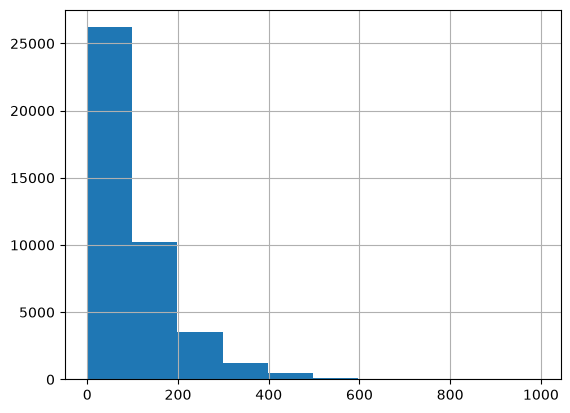

In [104]:
y["pm2.5"].hist()

We can split the target `y["pm2.5"]` into equally-distributed classes using the `qcut` function.

In [105]:
y["pm25_class"], bins = pd.qcut(
    y["pm2.5"],
    q=4,
    labels=["low", "moderate", "high", "very high"],
    retbins=True
)

print(bins)
print(y["pm25_class"].value_counts().sort_index())

[  0.  29.  72. 137. 994.]
pm25_class
low          10569
moderate     10330
high         10459
very high    10399
Name: count, dtype: int64


In [106]:
y

,pm2.5,pm25_class
24,129.0,high
25,148.0,very high
26,159.0,very high
27,181.0,very high
28,138.0,very high
...,...,...
43819,8.0,low
43820,10.0,low
43821,10.0,low
43822,8.0,low


# Task 2: Feature Normalisation & Transformation

## 2.1 Normalise Numerical Features:

First, we survey all features:

In [107]:
X.info()

<class 'pandas.DataFrame'>
Index: 41757 entries, 24 to 43823
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   year    41757 non-null  int64  
 1   month   41757 non-null  int64  
 2   day     41757 non-null  int64  
 3   hour    41757 non-null  int64  
 4   DEWP    41757 non-null  int64  
 5   TEMP    41757 non-null  float64
 6   PRES    41757 non-null  float64
 7   cbwd    41757 non-null  str    
 8   Iws     41757 non-null  float64
 9   Is      41757 non-null  int64  
 10  Ir      41757 non-null  int64  
dtypes: float64(3), int64(7), str(1)
memory usage: 3.9 MB


And preview the numerical features before scaling. The `describe()` function provides some summary statistics values for each numerical feature:

In [108]:
X.describe()

,year,month,day,hour,DEWP,TEMP,PRES,Iws,Is,Ir
count,41757.000000,41757.000000,41757.000000,41757.000000,41757.000000,41757.000000,41757.000000,41757.000000,41757.000000,41757.000000
mean,2012.042771,6.513758,15.685514,11.502311,1.750174,12.401561,1016.442896,23.866747,0.055344,0.194866
std,1.415311,3.454199,8.785539,6.924848,14.433658,12.175215,10.300733,49.617495,0.778875,1.418165
min,2010.000000,1.000000,1.000000,0.000000,-40.000000,-19.000000,991.000000,0.450000,0.000000,0.000000
25%,2011.000000,4.000000,8.000000,5.000000,-10.000000,2.000000,1008.000000,1.790000,0.000000,0.000000
50%,2012.000000,7.000000,16.000000,12.000000,2.000000,14.000000,1016.000000,5.370000,0.000000,0.000000
75%,2013.000000,10.000000,23.000000,18.000000,15.000000,23.000000,1025.000000,21.910000,0.000000,0.000000
max,2014.000000,12.000000,31.000000,23.000000,28.000000,42.000000,1046.000000,565.490000,27.000000,36.000000


As well as seeing histograms of these features

array([[<Axes: title={'center': 'year'}>,
        <Axes: title={'center': 'month'}>,
        <Axes: title={'center': 'day'}>,
        <Axes: title={'center': 'hour'}>,
        <Axes: title={'center': 'DEWP'}>],
       [<Axes: title={'center': 'TEMP'}>,
        <Axes: title={'center': 'PRES'}>,
        <Axes: title={'center': 'Iws'}>, <Axes: title={'center': 'Is'}>,
        <Axes: title={'center': 'Ir'}>]], dtype=object)

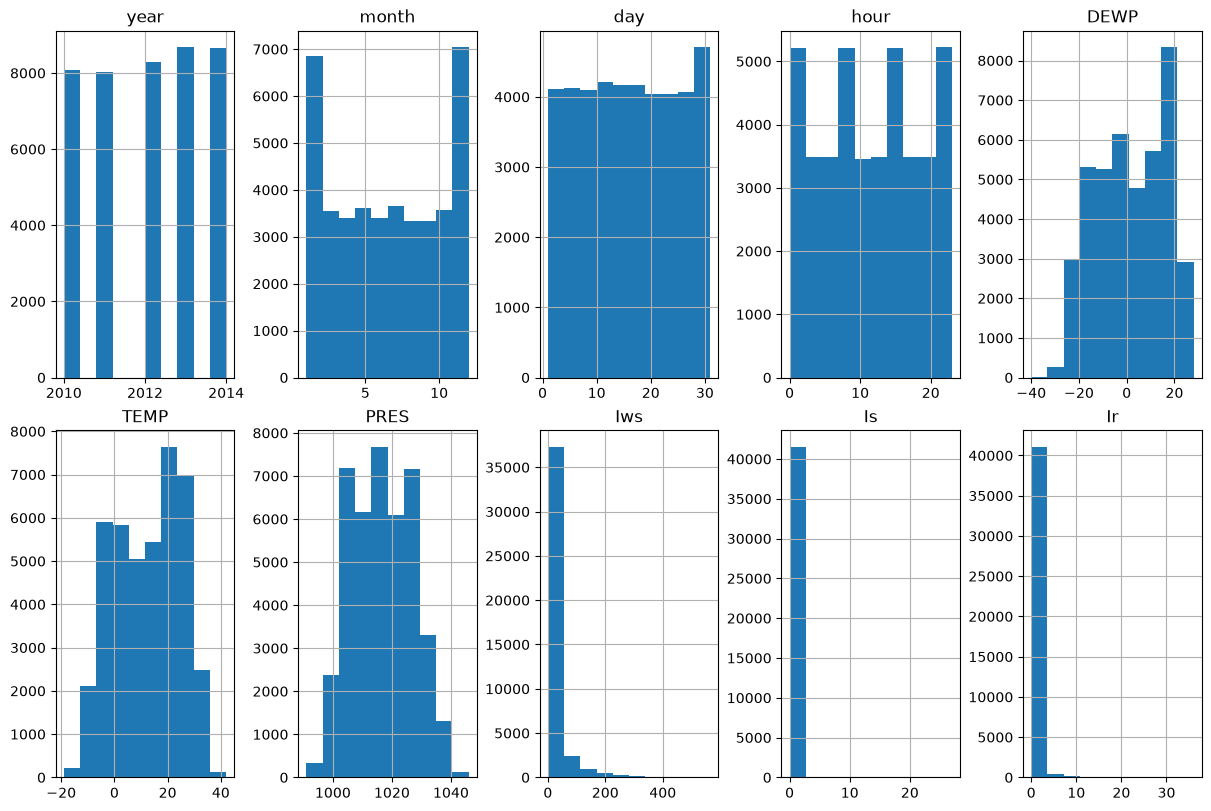

In [109]:
from PIL.ImageFont import Layout
import matplotlib.pyplot as plt

fig, axes = plt.subplots(ncols=5, nrows=2, figsize = (12, 8), layout = "constrained")
X.hist(ax=axes)

Based on the graphs, the numerical features will therefore be scaled as follows:

| **Feature** | **Scaling** |
|:-:|:-:|
| `year` | `MinMaxScaler` |
| `month` | `MinMaxScaler` |
| `day` | `MinMaxScaler` |
| `hour`| `MinMaxScaler` |
| `DEWP` | `StandardScaler` |
| `Iws` | `RobustScaler` |
| `Is` | `MinMaxScaler` |
| `Ir` | `MinMaxScaler` |

In [110]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

standard_cols = ["DEWP", "TEMP", "PRES"]
robust_cols = ["Iws"]
minmax_cols = ["year", "month", "day", "hour", "Is", "Ir"]

X_scaled = X.copy()

X_scaled[standard_cols] = StandardScaler().fit_transform(X[standard_cols])
X_scaled[robust_cols] = RobustScaler().fit_transform(X[robust_cols])

X_scaled[minmax_cols] = MinMaxScaler().fit_transform(X[minmax_cols])

X_scaled

,year,month,day,hour,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
24,0.0,0.0,0.033333,0.000000,-1.229791,-1.347143,0.345329,SE,-0.177932,0.000000,0.0
25,0.0,0.0,0.033333,0.043478,-1.160508,-1.347143,0.345329,SE,-0.133698,0.000000,0.0
26,0.0,0.0,0.033333,0.086957,-0.883375,-1.429278,0.442411,SE,-0.089463,0.000000,0.0
27,0.0,0.0,0.033333,0.130435,-0.606241,-1.429278,0.539493,SE,-0.000497,0.037037,0.0
28,0.0,0.0,0.033333,0.173913,-0.606241,-1.429278,0.539493,SE,0.043738,0.074074,0.0
...,...,...,...,...,...,...,...,...,...,...,...
43819,1.0,1.0,1.000000,0.826087,-1.714775,-1.182873,1.704472,NW,11.262425,0.000000,0.0
43820,1.0,1.0,1.000000,0.869565,-1.645491,-1.265008,1.704472,NW,11.551193,0.000000,0.0
43821,1.0,1.0,1.000000,0.913043,-1.645491,-1.265008,1.704472,NW,11.795726,0.000000,0.0
43822,1.0,1.0,1.000000,0.956522,-1.645491,-1.347143,1.704472,NW,11.995527,0.000000,0.0


## 2.2 Encode Categorical/Other Features:

We know that `cbwd` is a categorical feature. So we preview the categories:

In [111]:
pd.Categorical(X["cbwd"])

['SE', 'SE', 'SE', 'SE', 'SE', ..., 'NW', 'NW', 'NW', 'NW', 'NW']
Length: 41757
Categories (4, str): ['NE', 'NW', 'SE', 'cv']

Due to the small number of categories, we can perform _one-hot encoding_:

In [112]:
X_scaled = pd.get_dummies(
    X_scaled, 
    columns=["cbwd"],
    dtype = int
)

X_scaled

,year,month,day,hour,DEWP,TEMP,PRES,Iws,Is,Ir,cbwd_NE,cbwd_NW,cbwd_SE,cbwd_cv
24,0.0,0.0,0.033333,0.000000,-1.229791,-1.347143,0.345329,-0.177932,0.000000,0.0,0,0,1,0
25,0.0,0.0,0.033333,0.043478,-1.160508,-1.347143,0.345329,-0.133698,0.000000,0.0,0,0,1,0
26,0.0,0.0,0.033333,0.086957,-0.883375,-1.429278,0.442411,-0.089463,0.000000,0.0,0,0,1,0
27,0.0,0.0,0.033333,0.130435,-0.606241,-1.429278,0.539493,-0.000497,0.037037,0.0,0,0,1,0
28,0.0,0.0,0.033333,0.173913,-0.606241,-1.429278,0.539493,0.043738,0.074074,0.0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43819,1.0,1.0,1.000000,0.826087,-1.714775,-1.182873,1.704472,11.262425,0.000000,0.0,0,1,0,0
43820,1.0,1.0,1.000000,0.869565,-1.645491,-1.265008,1.704472,11.551193,0.000000,0.0,0,1,0,0
43821,1.0,1.0,1.000000,0.913043,-1.645491,-1.265008,1.704472,11.795726,0.000000,0.0,0,1,0,0
43822,1.0,1.0,1.000000,0.956522,-1.645491,-1.347143,1.704472,11.995527,0.000000,0.0,0,1,0,0


In [113]:
X_scaled.describe()

,year,month,day,hour,DEWP,TEMP,PRES,Iws,Is,Ir,cbwd_NE,cbwd_NW,cbwd_SE,cbwd_cv
count,41757.000000,41757.000000,41757.000000,41757.000000,4.175700e+04,4.175700e+04,4.175700e+04,41757.000000,41757.000000,41757.000000,41757.000000,41757.000000,41757.000000,41757.000000
mean,0.510693,0.501251,0.489517,0.500100,6.534196e-17,-7.078712e-17,-2.118168e-15,0.919321,0.002050,0.005413,0.113897,0.322916,0.348995,0.214192
std,0.353828,0.314018,0.292851,0.301080,1.000012e+00,1.000012e+00,1.000012e+00,2.466078,0.028847,0.039393,0.317690,0.467596,0.476658,0.410265
min,0.000000,0.000000,0.000000,0.000000,-2.892591e+00,-2.579169e+00,-2.470038e+00,-0.244533,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.250000,0.272727,0.233333,0.217391,-8.140912e-01,-8.543328e-01,-8.196501e-01,-0.177932,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.500000,0.545455,0.500000,0.521739,1.730880e-02,1.312878e-01,-4.299705e-02,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.750000,0.818182,0.733333,0.782609,9.179922e-01,8.705033e-01,8.307377e-01,0.822068,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.818676e+00,2.431069e+00,2.869452e+00,27.838966,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## 2.3

The following table provides the transformation used per-feature:

| **Feature** | **Transform** | **Method** |
|:-:|:-:|:-:|
| `year` | Scaled | `MinMaxScaler` |
| `month` | Scaled | `MinMaxScaler` |
| `day` | Scaled | `MinMaxScaler` |
| `hour`| Scaled | `MinMaxScaler` |
| `DEWP` | Scaled | `StandardScaler` |
| `Iws` |  Scaled |`RobustScaler` |
| `Is` | Scaled | `MinMaxScaler` |
| `Ir` | Scaled | `MinMaxScaler` |
| `cbwd` | Encoded | One-hot Encoding |


The numerical features are scaled, per their graphed distributions in section 2.1. The feature `cbwd` was encoded using one-hot encoding, per the fact that it has only `4` values with no order, as the values represent different wind conditions / wind directions.

Scaling can help algorithms such as gradient descent converge faster and helps ensure numerical stability as features with larger magnitudes can not disproportionately influence algorithms. 

# Task 3: Feature Engineering

First, we cyclically encode the month and hour numbers. The reason is that as they are cyclical features; i.e. this means that there are no "jumps" as the time moves from 23:00 to 0:00

In [114]:
import numpy as np

X_engineered = X.copy()

X_engineered["month_sin"] = np.sin(2 * np.pi * X["month"] / 12)
X_engineered["month_cos"] = np.cos(2 * np.pi * X["month"] / 12)

X_engineered["hour_sin"] = np.sin(2 * np.pi * X["hour"] / 24)
X_engineered["hour_cos"] = np.cos(2 * np.pi * X["hour"] / 24)

X_engineered

,year,month,day,hour,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir,month_sin,month_cos,hour_sin,hour_cos
24,2010,1,2,0,-16,-4.0,1020.0,SE,1.79,0,0,5.000000e-01,0.866025,0.000000,1.000000
25,2010,1,2,1,-15,-4.0,1020.0,SE,2.68,0,0,5.000000e-01,0.866025,0.258819,0.965926
26,2010,1,2,2,-11,-5.0,1021.0,SE,3.57,0,0,5.000000e-01,0.866025,0.500000,0.866025
27,2010,1,2,3,-7,-5.0,1022.0,SE,5.36,1,0,5.000000e-01,0.866025,0.707107,0.707107
28,2010,1,2,4,-7,-5.0,1022.0,SE,6.25,2,0,5.000000e-01,0.866025,0.866025,0.500000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43819,2014,12,31,19,-23,-2.0,1034.0,NW,231.97,0,0,-2.449294e-16,1.000000,-0.965926,0.258819
43820,2014,12,31,20,-22,-3.0,1034.0,NW,237.78,0,0,-2.449294e-16,1.000000,-0.866025,0.500000
43821,2014,12,31,21,-22,-3.0,1034.0,NW,242.70,0,0,-2.449294e-16,1.000000,-0.707107,0.707107
43822,2014,12,31,22,-22,-4.0,1034.0,NW,246.72,0,0,-2.449294e-16,1.000000,-0.500000,0.866025


Then, we calculate the _dewpoint spread_, which is the temperature subtracted by the dew point. 

In [115]:
X_engineered["dewpoint_spread"] = X["TEMP"] - X["DEWP"]
X_engineered["dewpoint_spread"].describe()


count    41757.000000
mean        10.651388
std          8.186658
min         -1.000000
25%          4.000000
50%          9.000000
75%         16.000000
max         51.000000
Name: dewpoint_spread, dtype: float64

We also notice that `Iws` has a strongly right-skewed distribution, with many large positive values. Therefore, we transform it to a logarithmic form for more numerical stability.

In [116]:
import numpy as np
X_engineered["log_Iws"] = np.log1p(X["Iws"])
X_engineered["log_Iws"].describe()

count    41757.000000
mean         2.183639
std          1.331706
min          0.371564
25%          1.026042
50%          1.851599
75%          3.131573
max          6.339459
Name: log_Iws, dtype: float64

We can also calculate the _relative humidity_ $\text{RH}$, using the formula:

$$
\text{RH} = 100 \exp\left( \frac{bD}{c + D} - \frac{bT}{c + T} \right)
$$

where $b = 17.625, c = 243.04$; and $D, T$ are the original dew point and temperature measurements.

In [117]:
b = 17.625
c = 243.04

T = X["TEMP"]
D = X["DEWP"]

X_engineered["RH"] = 100 * np.exp(
    (b * D / (c + D))
    - (b * T / (c + T))
)

X_engineered["RH"].describe()

count    41757.000000
mean        54.757360
std         25.946002
min          2.688797
25%         31.482728
50%         55.321861
75%         78.062864
max        106.779740
Name: RH, dtype: float64

As relative humidity is a percentage from 0-100; the existence of the max value larger than 100 needs investigating...

In [118]:
X_engineered["RH"].nlargest(10)

6727    106.77974
1415    100.00000
1420    100.00000
1739    100.00000
1855    100.00000
6552    100.00000
6580    100.00000
6581    100.00000
6674    100.00000
6675    100.00000
Name: RH, dtype: float64

Thus, it is a single outlier; and can be safely clamped to 100.

In [119]:
X_engineered["RH"] = X_engineered["RH"].clip(lower=0, upper=100)
X_engineered["RH"].describe()

count    41757.000000
mean        54.757198
std         25.945698
min          2.688797
25%         31.482728
50%         55.321861
75%         78.062864
max        100.000000
Name: RH, dtype: float64

Finally, we fix this

In [120]:

X_engineered = pd.get_dummies(
    X_engineered,
    columns=["cbwd"],
    dtype=int
)


X_engineered

,year,month,day,hour,DEWP,TEMP,PRES,Iws,Is,Ir,...,month_cos,hour_sin,hour_cos,dewpoint_spread,log_Iws,RH,cbwd_NE,cbwd_NW,cbwd_SE,cbwd_cv
24,2010,1,2,0,-16,-4.0,1020.0,1.79,0,0,...,0.866025,0.000000,1.000000,12.0,1.026042,38.784785,0,0,1,0
25,2010,1,2,1,-15,-4.0,1020.0,2.68,0,0,...,0.866025,0.258819,0.965926,11.0,1.302913,42.130158,0,0,1,0
26,2010,1,2,2,-11,-5.0,1021.0,3.57,0,0,...,0.866025,0.500000,0.866025,6.0,1.519513,62.793843,0,0,1,0
27,2010,1,2,3,-7,-5.0,1022.0,5.36,1,0,...,0.866025,0.707107,0.707107,2.0,1.850028,85.857955,0,0,1,0
28,2010,1,2,4,-7,-5.0,1022.0,6.25,2,0,...,0.866025,0.866025,0.500000,2.0,1.981001,85.857955,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43819,2014,12,31,19,-23,-2.0,1034.0,231.97,0,0,...,1.000000,-0.965926,0.258819,21.0,5.450910,18.340886,0,1,0,0
43820,2014,12,31,20,-22,-3.0,1034.0,237.78,0,0,...,1.000000,-0.866025,0.500000,19.0,5.475543,21.568601,0,1,0,0
43821,2014,12,31,21,-22,-3.0,1034.0,242.70,0,0,...,1.000000,-0.707107,0.707107,19.0,5.495938,21.568601,0,1,0,0
43822,2014,12,31,22,-22,-4.0,1034.0,246.72,0,0,...,1.000000,-0.500000,0.866025,18.0,5.512299,23.240409,0,1,0,0


The new features can be justified as follows:

| **New Feature** | **EDA Motivation** | **Engineering Meaning** |
|:-:|:-:|:-:|
| `dewpoint_spread` | `TEMP` and `DEWP` vary, and their differences indicates proximity to saturation | Measures the difference between air temperature and dew point; smaller values generally indicate more humid conditions. |
| `hour_sin`, `hour_cos` | The `hour` feature contains values from `0` to `23`, representing the daily cycle | Representing as sine and cosine encode the cyclical nature, allowing the model to represent daily patterns and variations |
|`month_sin`, `month_cos` | Similar to the `hour` feature, but from `1` to `12` | Similar to the `hour_sin`, `hour_cos` features |
| `log_Iws` | `Iws` is heavily right-skewed; with a median of `5.37` and max of `565.49` | Compresses large cummulative speed values may help with numerical stability |
| `RH` | `TEMP` and `DEWP` were close and have high correlation |  Temperature and Dew Point were combined using the Magnus Approximation to estimate relative humidity, a physically interpretable indicator of moisture | 

# Task 4: Decision Tree Modelling & Comparison

We split the dataset into train and test datasets; before modelling

In [121]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_engineered,
    y["pm2.5"],
    test_size=0.3,
    random_state=42
)

# type enforce
X_train = pd.DataFrame(X_train)
X_test = pd.DataFrame(X_test)
y_train = pd.DataFrame(y_train)
y_test = pd.DataFrame(y_test)

We collect the dataset as follows:

Set 1: Original columns (encoded)

In [122]:
original_cols = [
    "year", "month", "day", "hour",
    "DEWP", "TEMP", "PRES",
    "Iws", "Is", "Ir",
    "cbwd_NE", "cbwd_NW", "cbwd_SE", "cbwd_cv"
]
set1 = original_cols
set1

['year',
 'month',
 'day',
 'hour',
 'DEWP',
 'TEMP',
 'PRES',
 'Iws',
 'Is',
 'Ir',
 'cbwd_NE',
 'cbwd_NW',
 'cbwd_SE',
 'cbwd_cv']

Set 2: Top correlated features

In [123]:
correlations = X_train.corrwith(y_train["pm2.5"])
set2 = correlations.abs().nlargest(5).index.to_list()
set2

['RH', 'dewpoint_spread', 'log_Iws', 'Iws', 'cbwd_NW']

Set 3: Original + engineered features

In [124]:
engineered_cols = [
    "RH", "dewpoint_spread", "log_Iws",
    "month_sin", "month_cos",
    "hour_sin", "hour_cos"
]


set3 = original_cols + engineered_cols
set3

['year',
 'month',
 'day',
 'hour',
 'DEWP',
 'TEMP',
 'PRES',
 'Iws',
 'Is',
 'Ir',
 'cbwd_NE',
 'cbwd_NW',
 'cbwd_SE',
 'cbwd_cv',
 'RH',
 'dewpoint_spread',
 'log_Iws',
 'month_sin',
 'month_cos',
 'hour_sin',
 'hour_cos']

Set 4: PCA, first 5 PCs

In [125]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_pca_input = scaler.fit_transform(X_train[set3])
X_test_pca_input = scaler.transform(X_test[set3])

pca = PCA(n_components=5)

X_train_pca = pd.DataFrame(
    pca.fit_transform(X_train),
    columns=[f"PC{i}" for i in range(1, 6)],
    index=X_train.index
)

X_test_pca = pd.DataFrame(
    pca.transform(X_test),
    columns=X_train_pca.columns,
    index=X_test.index
)

X_train_pca

,PC1,PC2,PC3,PC4,PC5
27579,-18.948090,-15.744452,-25.951867,7.564157,-6.996950
26613,-23.839493,5.178348,-24.625630,-2.562857,11.769745
11613,2.141285,38.801085,1.997484,12.722007,9.120370
2745,89.707864,35.585902,2.920001,8.994751,-2.031957
4816,-15.936927,11.409981,25.505170,4.013619,2.874060
...,...,...,...,...,...
6878,37.046123,-20.092039,15.565303,-1.538407,0.435628
12359,-10.485952,-23.256862,22.382166,14.191541,6.642247
40166,-25.222904,6.026266,26.505543,-14.868294,1.437565
951,-12.508805,-37.505823,-5.779239,-6.331096,2.022341


Set 5: Domain-selected features

In [126]:
# Set 5: Domain-selected meteorological features
set5 = [
    "RH",
    "Iws",
    "TEMP",
    "PRES",
    "Is",
    "Ir",
    "cbwd_NE", "cbwd_NW", "cbwd_SE", "cbwd_cv"
]
set5

['RH',
 'Iws',
 'TEMP',
 'PRES',
 'Is',
 'Ir',
 'cbwd_NE',
 'cbwd_NW',
 'cbwd_SE',
 'cbwd_cv']

# Task 5: Results Comparison Table

From there, we implement the trees!

In [127]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

datasets = [
    (X_train[set1], X_test[set1]),
    (X_train[set2], X_test[set2]),
    (X_train[set3], X_test[set3]),
    (X_train_pca, X_test_pca),
    (X_train[set5], X_test[set5])
]

names = [
    "Original Features",
    "Top 5 Correlated",
    "Original + Engineered",
    "PCA (5 Components)",
    "Domain Selected"
]

trees = []
results = []

# Support either Series or single-column DataFrame targets
y_train_target = (
    y_train["pm2.5"] if isinstance(y_train, pd.DataFrame)
    else y_train
)
y_test_target = (
    y_test["pm2.5"] if isinstance(y_test, pd.DataFrame)
    else y_test
)

for name, (X_tr, X_te) in zip(names, datasets):
    model = DecisionTreeRegressor(random_state=42)

    model.fit(X_tr, y_train_target)
    y_pred = model.predict(X_te)

    trees.append(model)

    results.append({
        "Feature Set": name,
        "N Features": X_tr.shape[1],
        "MAE": mean_absolute_error(y_test_target, y_pred),
        "MSE": mean_squared_error(y_test_target, y_pred),
        "RMSE": root_mean_squared_error(y_test_target, y_pred),
        "R^2": r2_score(y_test_target, y_pred)
    })

results_df = pd.DataFrame(results)
results_df["R^2 (%)"] = results_df["R^2"] * 100

results_df.round(4)

,Feature Set,N Features,MAE,MSE,RMSE,R^2,R^2 (%)
0,Original Features,14,28.5304,2736.1838,52.3085,0.6799,67.9908
1,Top 5 Correlated,5,63.4824,9048.9815,95.1261,-0.0586,-5.8594
2,Original + Engineered,21,32.2514,3333.3017,57.7348,0.6101,61.0054
3,PCA (5 Components),5,57.1683,8262.1280,90.8962,0.0335,3.3456
4,Domain Selected,10,60.3379,9188.8613,95.8585,-0.0750,-7.4958


We sort the result bty RMSE, lower is better:

In [128]:

results_df.sort_values("RMSE")


,Feature Set,N Features,MAE,MSE,RMSE,R^2,R^2 (%)
0,Original Features,14,28.530412,2736.183828,52.308545,0.679908,67.990775
2,Original + Engineered,21,32.251437,3333.301724,57.734753,0.610054,61.005396
3,PCA (5 Components),5,57.168343,8262.127953,90.896248,0.033456,3.345560
1,Top 5 Correlated,5,63.482403,9048.981474,95.126135,-0.058594,-5.859440
4,Domain Selected,10,60.337910,9188.861339,95.858549,-0.074958,-7.495823


We can see that on an untuned Decision Tree, the original features perform the best.

# Task 6: Model Improvement

## 6.1: SVR Training

We train a SVR model.

In [129]:

from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score
)

svr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(kernel="rbf"))
])

# Train the SVR
svr_model.fit(X_train[set3], y_train_target)

# Predict the test set
y_pred_svr = svr_model.predict(X_test[set3])

# Evaluate
svr_results = {
    "MAE": mean_absolute_error(y_test_target, y_pred_svr),
    "MSE": mean_squared_error(y_test_target, y_pred_svr),
    "RMSE": root_mean_squared_error(y_test_target, y_pred_svr),
    "R^2": r2_score(y_test_target, y_pred_svr)
}

pd.Series(svr_results)


MAE       44.753580
MSE     5140.458100
RMSE      71.696988
R^2        0.398644
dtype: float64

## 6.2: 5-fold cross validation

We perform 5-fold cross validation

In [130]:

from sklearn.model_selection import KFold, cross_validate

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    svr_model,
    X_train[set3],
    y_train_target,
    cv=cv,
    scoring={
        "R^2": "r2",
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error"
    },
    n_jobs=1
)

cv_df = pd.DataFrame({
    "Fold": range(1, 6),
    "R^2": cv_results["test_R^2"],
    "MAE": -cv_results["test_MAE"],
    "RMSE": -cv_results["test_RMSE"]
})

cv_df


,Fold,R^2,MAE,RMSE
0,1,0.377039,45.619489,73.317930
1,2,0.387183,45.023667,71.349364
2,3,0.389577,45.445564,72.853069
3,4,0.382656,45.368202,71.875656
4,5,0.403327,44.639417,69.962221


In [131]:

cv_summary = cv_df[["R^2", "MAE", "RMSE"]].agg(
    ["mean", "std"]
)

cv_summary


,R^2,MAE,RMSE
mean,0.387956,45.219268,71.871648
std,0.009833,0.389889,1.320381


# Task 7: Hyperparameter Tuning

We use `GridSearchCV` with a `RBF` kernel to perform hyperparameter tuning.

In [132]:

from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

# Same SVR pipeline as Task 6
svr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR())
])

# Hyperparameter combinations to test
param_grid = [
    {
        "svr__kernel": ["linear"],
        "svr__C": [0.1, 1, 10],
        "svr__epsilon": [0.1, 1]
    },
    {
        "svr__kernel": ["rbf"],
        "svr__C": [0.1, 1, 10],
        "svr__epsilon": [0.1, 1],
        "svr__gamma": ["scale", 0.01]
    }
]

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=svr_pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=1,
    verbose=2,
    refit=True
)

grid_search.fit(X_train[set3], y_train_target)


Fitting 5 folds for each of 18 candidates, totalling 90 fits
[CV] END ...svr__C=0.1, svr__epsilon=0.1, svr__kernel=linear; total time=   2.5s
[CV] END ...svr__C=0.1, svr__epsilon=0.1, svr__kernel=linear; total time=   2.5s
[CV] END ...svr__C=0.1, svr__epsilon=0.1, svr__kernel=linear; total time=   2.5s
[CV] END ...svr__C=0.1, svr__epsilon=0.1, svr__kernel=linear; total time=   2.5s
[CV] END ...svr__C=0.1, svr__epsilon=0.1, svr__kernel=linear; total time=   2.5s
[CV] END .....svr__C=0.1, svr__epsilon=1, svr__kernel=linear; total time=   2.4s
[CV] END .....svr__C=0.1, svr__epsilon=1, svr__kernel=linear; total time=   2.4s


[CV] END .....svr__C=0.1, svr__epsilon=1, svr__kernel=linear; total time=   2.4s
[CV] END .....svr__C=0.1, svr__epsilon=1, svr__kernel=linear; total time=   2.6s
[CV] END .....svr__C=0.1, svr__epsilon=1, svr__kernel=linear; total time=   2.4s
[CV] END .....svr__C=1, svr__epsilon=0.1, svr__kernel=linear; total time=   3.1s
[CV] END .....svr__C=1, svr__epsilon=0.1, svr__kernel=linear; total time=   2.7s
[CV] END .....svr__C=1, svr__epsilon=0.1, svr__kernel=linear; total time=   2.8s
[CV] END .....svr__C=1, svr__epsilon=0.1, svr__kernel=linear; total time=   2.7s
[CV] END .....svr__C=1, svr__epsilon=0.1, svr__kernel=linear; total time=   2.8s
[CV] END .......svr__C=1, svr__epsilon=1, svr__kernel=linear; total time=   2.7s
[CV] END .......svr__C=1, svr__epsilon=1, svr__kernel=linear; total time=   2.7s
[CV] END .......svr__C=1, svr__epsilon=1, svr__kernel=linear; total time=   2.7s
[CV] END .......svr__C=1, svr__epsilon=1, svr__kernel=linear; total time=   2.8s
[CV] END .......svr__C=1, sv

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...svr', SVR())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'svr__C': [0.1, 1, ...], 'svr__epsilon': [0.1, 1], 'svr__kernel': ['linear']}, {'svr__C': [0.1, 1, ...], 'svr__epsilon': [0.1, 1], 'svr__gamma': ['scale', 0.01], 'svr__kernel': ['rbf']}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t t

Now, we get the best hyperparameter and implement 5-fold cross-validation.

In [133]:
best_svr = grid_search.best_estimator_

y_pred_tuned = best_svr.predict(X_test[set3])

tuned_results = {
    "MAE": mean_absolute_error(y_test_target, y_pred_tuned),
    "RMSE": root_mean_squared_error(y_test_target, y_pred_tuned),
    "R^2": r2_score(y_test_target, y_pred_tuned)
}

pd.Series(tuned_results)

MAE     40.112593
RMSE    63.544887
R^2      0.527620
dtype: float64

and implement 5-fold CV 

In [134]:
best_index = grid_search.best_index_
cv_results = grid_search.cv_results_

fold_rmse = [
    -cv_results[f"split{i}_test_score"][best_index]
    for i in range(5)
]

print("5-fold RMSE:", fold_rmse)
print("Mean CV RMSE:", np.mean(fold_rmse))
print("CV RMSE std:", np.std(fold_rmse))

5-fold RMSE: [np.float64(64.69669344092479), np.float64(62.399385307395775), np.float64(63.70473322508756), np.float64(63.13062791670754), np.float64(60.98166959872958)]
Mean CV RMSE: 62.98262189776905
CV RMSE std: 1.2510289228568294


And compare the original and tuned models

In [135]:
comparison = pd.DataFrame([
    {
        "Model": "Original SVR",
        **svr_results
    },
    {
        "Model": "Tuned SVR",
        **tuned_results
    }
])

comparison

,Model,MAE,MSE,RMSE,R^2
0,Original SVR,44.753580,5140.4581,71.696988,0.398644
1,Tuned SVR,40.112593,NaN,63.544887,0.527620


In [136]:
from IPython.display import display
from sklearn.model_selection import cross_validate

tuned_cv = cross_validate(
    best_svr,
    X_train[set3],
    y_train_target,
    cv=cv,
    scoring={
        "R^2": "r2",
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error"
    },
    n_jobs=1
)

tuned_cv_df = pd.DataFrame({
    "Fold": range(1, 6),
    "R^2": tuned_cv["test_R^2"],
    "MAE": -tuned_cv["test_MAE"],
    "RMSE": -tuned_cv["test_RMSE"]
})

display(tuned_cv_df)
display(tuned_cv_df[["R^2", "MAE", "RMSE"]].agg(["mean", "std"]))


,Fold,R^2,MAE,RMSE
0,1,0.514930,40.483899,64.696693
1,2,0.531282,39.947500,62.399385
2,3,0.533256,40.464398,63.704733
3,4,0.523740,40.312540,63.130628
4,5,0.546677,39.325208,60.981670


,R^2,MAE,RMSE
mean,0.529977,40.106709,62.982622
std,0.011797,0.486999,1.398693


# Task 8: Feature Selection

We implement Feature Regression using univariate F-statistics, and the (optimal) tuned values above

In [137]:
from sklearn.feature_selection import SelectKBest, f_regression

kbest_svr = Pipeline([
    ("selection", SelectKBest(score_func=f_regression, k=5)),
    ("scaler", StandardScaler()),
    ("svr", SVR(
        kernel="rbf",
        C=10,
        epsilon=1,
        gamma="scale"
    ))
])

kbest_svr

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('selection', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"score_func score_func: callable, default=f_classifFunction taking two arrays X and y, and returning a pair of arrays(scores, pvalues) or a single array with scores.Default is f_classif (see below ""See Also""). The default function onlyworks with classification tasks... versionadded:: 0.18",<function f_r...x7fdd5c5db8a0>
,"k k: int or ""all"", default=10Number of top features to select.The ""all"" option bypasses selection, for use in a parameter search.",5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",1


then we evaluate the result

In [138]:
kbest_svr.fit(X_train[set3], y_train_target)

y_pred_kbest = kbest_svr.predict(X_test[set3])

kbest_results = {
    "MAE": mean_absolute_error(y_test_target, y_pred_kbest),
    "MSE": mean_squared_error(y_test_target, y_pred_kbest),
    "RMSE": root_mean_squared_error(y_test_target, y_pred_kbest),
    "R^2": r2_score(y_test_target, y_pred_kbest)
}

pd.Series(kbest_results)


MAE       52.831920
MSE     6845.080744
RMSE      82.735003
R^2        0.199229
dtype: float64

what features?

In [139]:
selector = kbest_svr.named_steps["selection"]

feature_scores = pd.DataFrame({
    "Feature": set3,
    "F-score": selector.scores_,
    "Selected": selector.get_support()
})

feature_scores.sort_values(
    "F-score",
    ascending=False
)


,Feature,F-score,Selected
14,RH,7370.948672,True
15,dewpoint_spread,7036.272435,True
16,log_Iws,3341.876225,True
7,Iws,1913.903832,True
11,cbwd_NW,1425.170052,True
4,DEWP,908.767537,False
13,cbwd_cv,724.038881,False
18,month_cos,345.469940,False
12,cbwd_SE,266.651163,False
20,hour_cos,246.655989,False


And once again, we perform 5-fold cross validation

In [140]:
from IPython.display import display
from sklearn.model_selection import KFold, cross_validate

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

kbest_cv = cross_validate(
    kbest_svr,
    X_train[set3],
    y_train_target,
    cv=cv,
    scoring={
        "R^2": "r2",
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error"
    },
    n_jobs=1
)

kbest_cv_df = pd.DataFrame({
    "Fold": range(1, 6),
    "R^2": kbest_cv["test_R^2"],
    "MAE": -kbest_cv["test_MAE"],
    "RMSE": -kbest_cv["test_RMSE"]
})

kbest_cv_df


,Fold,R^2,MAE,RMSE
0,1,0.204716,52.970127,82.840176
1,2,0.210580,52.429469,80.980156
2,3,0.205604,53.198855,83.109534
3,4,0.203424,52.985478,81.645394
4,5,0.214462,52.417642,80.274774


# Task 9: Dimensionality Reduction

We implement DR with PCA.

In [141]:

from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

pca_svr = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=10)),
    ("svr", SVR(
        kernel="rbf",
        C=10,
        epsilon=1,
        gamma="scale"
    ))
])

pca_svr


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('pca', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",10
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",Fa

with split eval

In [142]:
pca_svr.fit(X_train[set3], y_train_target)

y_pred_pca = pca_svr.predict(X_test[set3])

pca_results = {
    "MAE": mean_absolute_error(y_test_target, y_pred_pca),
    "MSE": mean_squared_error(y_test_target, y_pred_pca),
    "RMSE": root_mean_squared_error(y_test_target, y_pred_pca),
    "R^2": r2_score(y_test_target, y_pred_pca)
}

pd.Series(pca_results)


MAE       45.275150
MSE     5039.729514
RMSE      70.991052
R^2        0.410428
dtype: float64

and 5-fold CV

In [143]:

from sklearn.model_selection import KFold, cross_validate

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

pca_cv = cross_validate(
    pca_svr,
    X_train[set3],
    y_train_target,
    cv=cv,
    scoring={
        "R^2": "r2",
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error"
    },
    n_jobs=1
)

pca_cv_df = pd.DataFrame({
    "Fold": range(1, 6),
    "R^2": pca_cv["test_R^2"],
    "MAE": -pca_cv["test_MAE"],
    "RMSE": -pca_cv["test_RMSE"]
})

display(pca_cv_df)
display(pca_cv_df[["R^2", "MAE", "RMSE"]].agg(["mean", "std"]))


,Fold,R^2,MAE,RMSE
0,1,0.399588,45.545587,71.978774
1,2,0.416028,44.961808,69.649924
2,3,0.415949,45.456460,71.261949
3,4,0.405721,45.497071,70.520183
4,5,0.428179,44.639914,68.489749


,R^2,MAE,RMSE
mean,0.413093,45.220168,70.380116
std,0.010967,0.400578,1.365616


# Task 10: Final Results Table

Before implementing the final results table, we implement a SVM over the original features

In [144]:

from sklearn.base import clone
from sklearn.model_selection import cross_validate
from sklearn.metrics import r2_score, root_mean_squared_error

# Original features: 14 features, no tuning
original_svr = clone(svr_model)

# Train/test evaluation
original_svr.fit(X_train[set1], y_train_target)
original_pred = original_svr.predict(X_test[set1])

original_results = {
    "R^2": r2_score(y_test_target, original_pred),
    "RMSE": root_mean_squared_error(y_test_target, original_pred)
}

# Five-fold cross-validation
original_cv = cross_validate(
    original_svr,
    X_train[set1],
    y_train_target,
    cv=cv,
    scoring={
        "R^2": "r2",
        "RMSE": "neg_root_mean_squared_error"
    },
    n_jobs=1
)

original_cv_r2 = original_cv["test_R^2"].mean()
original_cv_rmse = -original_cv["test_RMSE"].mean()

print("Test:", original_results)
print("CV R^2:", original_cv_r2)
print("CV RMSE:", original_cv_rmse)


Test: {'R^2': 0.2381338736357287, 'RMSE': 80.7001582876639}
CV R^2: 0.21490227664097533
CV RMSE: 81.40078273066875


In [155]:

final_table = pd.DataFrame([
    {
        "SVM Model": "Original features",
        "Train-test R^2": original_results["R^2"],
        "CV R^2": original_cv_r2,
        "Train-test RMSE": original_results["RMSE"],
        "CV RMSE": original_cv_rmse
    },
    {
        "SVM Model": "With hyperparameter tuning",
        "Train-test R^2": tuned_results["R^2"],
        "CV R^2": tuned_cv_df["R^2"].mean(),
        "Train-test RMSE": tuned_results["RMSE"],
        "CV RMSE": tuned_cv_df["RMSE"].mean(),
    },
    {
        "SVM Model": "Feature selection + tuning",
        "Train-test R^2": kbest_results["R^2"],
        "CV R^2": kbest_cv_df["R^2"].mean(),
        "Train-test RMSE": kbest_results["RMSE"],
        "CV RMSE": kbest_cv_df["RMSE"].mean(),
    },
    {
        "SVM Model": "PCA + tuning",
        "Train-test R^2": pca_results["R^2"],
        "CV R^2": pca_cv_df["R^2"].mean(),
        "Train-test RMSE": pca_results["RMSE"],
        "CV RMSE": pca_cv_df["RMSE"].mean(),
    }
])

# final_table[["Train-test accuracy", "CV accuracy"]] = final_table[["Train-test R^2", "CV R^2"]] * 100
final_table.round(2)


,SVM Model,Train-test R^2,CV R^2,Train-test RMSE,CV RMSE
0,Original features,0.24,0.21,80.70,81.40
1,With hyperparameter tuning,0.53,0.53,63.54,62.98
2,Feature selection + tuning,0.20,0.21,82.74,81.77
3,PCA + tuning,0.41,0.41,70.99,70.38


The final results table is as follows:

| SVM Model                  |   Train-test R^2 |   CV R^2 |   Train-test RMSE |   CV RMSE |
|:---------------------------:|:-----------------:|:---------:|:------------------:|:----------:|
| Original features          |             0.24 |     0.21 |             80.7  |     81.4  |
| With hyperparameter tuning |             0.53 |     0.53 |             63.54 |     62.98 |
| Feature selection + tuning |             0.2  |     0.21 |             82.74 |     81.77 |
| PCA + tuning               |             0.41 |     0.41 |             70.99 |     70.38 |

1. Which preprocessing technique (normalisation, feature engineering, feature selection, or PCA) had the biggest impact on your model performance?

The technique with the largest impact on model performance is Feature Selection.

2. Did hyperparameter tuning significantly improve your SVM model? By how much?

HT improved the train-test $R^2$ by 0.29, the CV $R^2$ by 0.32, and reduces the RMSE by 21.3

3. Compare Decision Tree vs SVM - which performed better for your dataset?

Decision Trees performed better, with overall higher $R^2$ values.

4. Was there a trade-off between model performance and interpretability?

None; as the more-interpretable Decision Tree also performed better than the less-interpretable SVMs.